# Agent Inteligent pentru Deduplicare Alarme ICU

## Contextul etapei

In etapele anterioare:
- **Etapa 1** — am analizat datele si am demonstrat ca acelasi eveniment clinic apare sub formulari complet diferite
- **Etapa 2** — am transformat mesajele in vectori semantici de 384 dimensiuni (MiniLM) si am ales pragul optim de **0.80**

**Etapa 3 — Agentul:** acum grupam alarmele similare (deduplicare) si trimitem fiecare cluster la un agent GPT-4o care:

| Tool | Ce face |
|---|---|
| `classify_severity` | Determina severitatea consolidata a clusterului |
| `generate_unified_alarm` | Genereaza UN singur mesaj clar in loc de N alarme redundante |
| `explain_grouping` | Explica in limbaj natural (pentru medici/asistente) de ce alarmele au fost grupate |

**Rezultatul final:** in loc de 5 alarme identice pe dashboard, personalul medical vede o singura notificare consolidata cu prioritate si explicatie.

#### Incarcare librarii si module

In [1]:
import sys, os
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from dotenv import load_dotenv

from src.embedder import AlarmEmbedder
from src.deduplicator import AlarmDeduplicator
from src.agent import SilentICUAgent

load_dotenv()

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   'white',
    'text.color':       'black',
    'savefig.facecolor':'white',
})
os.makedirs('../data/results', exist_ok=True)
print('Succes')

Succes


#### Incarcare date si embeddings

In [2]:
CSV_PATH = '../data/raw/alarms_combined.csv'
EMBEDDINGS_PATH = '../data/embeddings/embeddings_minilm.npy'

df = pd.read_csv(CSV_PATH)
df['timestamp'] = pd.to_datetime(df['timestamp'])

embeddings = np.load(EMBEDDINGS_PATH)

print(f'Alarme incarcate : {len(df)}')
print(f'Shape embeddings : {embeddings.shape}')
print(f'\nColoane disponibile: {list(df.columns)}')
df.head(3)

Alarme incarcate : 1750
Shape embeddings : (1750, 384)

Coloane disponibile: ['alarm_id', 'timestamp', 'message', 'source', 'source_device', 'patient_id', 'true_group', 'severity', 'is_duplicate', 'data_source', 'is_true_alarm']


,alarm_id,timestamp,message,source,source_device,patient_id,true_group,severity,is_duplicate,data_source,is_true_alarm
0,1,2024-01-15 06:00:13,Poor electrode contact,IV Pump,BD Alaris System,Patient_009,disconnected_lead,LOW,False,simulated,True
1,2,2024-01-15 06:00:18,Electrode contact poor,EHR System,Epic Systems,Patient_009,disconnected_lead,LOW,False,simulated,True
2,3,2024-01-15 06:00:55,ECG lead off,Monitor C,Drager Infinity Delta,Patient_010,disconnected_lead,LOW,False,simulated,True


## 1. Deduplicare semantica

**AlarmDeduplicator** grupeaza alarmele similare folosind **Union-Find** pe perechi cu:
- cosine similarity >= **0.80** (pragul ales in Etapa 2)
- diferenta de timp <= **10 minute** (aceeasi fereastra clinica)
- acelasi `patient_id` (nu grupam alarme de la pacienti diferiti)

De ce Union-Find si nu threshold simplu?
Daca A similar cu B si B similar cu C (dar A si C nu sunt direct similare), tot descriu acelasi eveniment -> Union-Find propaga tranzitiv conexiunile.

In [3]:
THRESHOLD = 0.80
TIME_WINDOW = 10 # minute

dedup = AlarmDeduplicator(threshold=THRESHOLD, time_window_min=TIME_WINDOW)
df_result = dedup.fit(df, embeddings)

print('\n--- Statistici deduplicare ---')
stats = dedup.stats()
for k, v in stats.items():
    print(f'  {k:30}: {v}')

INFO: === AlarmDeduplicator: 1750 alarme ===
INFO: Threshold: 0.8 | Fereastra timp: 10 min
INFO: Calculare matrice similaritate pentru 1750 alarme...
INFO: Shape matrice: (1750, 1750)
INFO: Perechi similare gasite: 4475 (threshold=0.8, fereastra=10 min)
INFO: Clustere formate: 556 total (328 cu duplicate, 228 singleton)
INFO: Alarme suprimate (reduse la reprezentant): 1194 din 1750 (68.2%)



--- Statistici deduplicare ---
  total_alarms                  : 1750
  total_clusters                : 556
  duplicate_clusters            : 328
  singleton_clusters            : 228
  alarms_suppressed             : 1194
  deduplication_rate            : 0.6823
  threshold                     : 0.8
  time_window_min               : 10


#### Previzualizare DataFrame adnotat

Coloane noi adaugate de deduplicator:
- `cluster_id` - ID-ul clusterului din care face parte alarma
- `is_dedup_duplicate` - True daca alarma face parte dintr-un cluster cu > 1 element
- `cluster_size` - cate alarme sunt in cluster
- `cluster_severity` - severitatea maxima din cluster
- `is_representative` - True pentru alarma cea mai veche din cluster (cea afisata pe dashboard)

In [4]:
cols_show = ['alarm_id', 'timestamp', 'message', 'severity',
             'cluster_id', 'cluster_size', 'is_dedup_duplicate', 'is_representative']
df_result[cols_show].head(10)

,alarm_id,timestamp,message,severity,cluster_id,cluster_size,is_dedup_duplicate,is_representative
0,1,2024-01-15 06:00:13,Poor electrode contact,LOW,0,13,True,True
1,2,2024-01-15 06:00:18,Electrode contact poor,LOW,0,13,True,False
2,3,2024-01-15 06:00:55,ECG lead off,LOW,1,3,True,True
3,4,2024-01-15 06:01:10,Electrode contact poor,LOW,2,15,True,True
4,5,2024-01-15 06:01:46,Electrode contact poor,LOW,2,15,True,False
5,6,2024-01-15 06:01:56,ECG lead disconnect alarm,LOW,3,3,True,True
6,7,2024-01-15 06:03:01,Glucose above target range,MEDIUM,4,2,True,True
7,8,2024-01-15 06:03:13,Elevated blood sugar detected,MEDIUM,5,6,True,True
8,9,2024-01-15 06:03:32,High blood glucose level,MEDIUM,6,13,True,True
9,10,2024-01-15 06:03:55,Increased heart rate detected,HIGH,7,2,True,True


### Distributia dimensiunilor clusterelor

Cate clustere au 1 alarma (singleton), cate au 2, 3, ...?

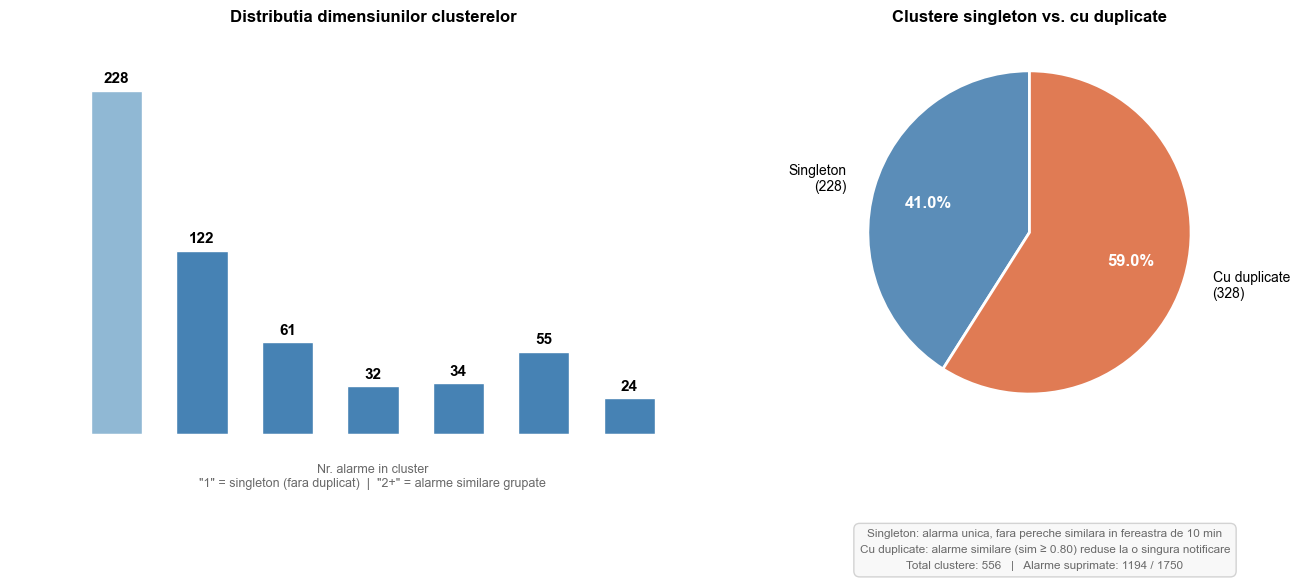

Salvat: clusterDistribution.png


In [5]:
summary = dedup.cluster_summary()
stats = dedup.stats()

def bucket(x):
    if x <= 5: return str(x)
    elif x <= 10: return '6-10'
    else: return '11+'

bucketed = summary['size'].apply(bucket).value_counts()
order = ['1', '2', '3', '4', '5', '6-10', '11+']
bucketed = bucketed.reindex([o for o in order if o in bucketed.index]).dropna().astype(int)

fig = plt.figure(figsize=(14, 6), facecolor='white')

# ── Stanga ────────────────────────────────────────────────
ax1 = fig.add_subplot(1, 2, 1)
ax1.set_facecolor('white')

x = range(len(bucketed))
colors = ['#90B8D4'] + ['steelblue'] * (len(bucketed) - 1)
bars = ax1.bar(x, bucketed.values, color=colors, edgecolor='white', width=0.6)

# etichete X
ax1.set_xticks(list(x))
ax1.set_xticklabels(list(bucketed.index), fontsize=11)

# valori deasupra barelor — offset fix in unitati absolute
for bar, val in zip(bars, bucketed.values):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 3,          # +3 unitati fixe, nu procent
             str(val),
             ha='center', va='bottom', fontsize=11, fontweight='bold', color='black')

ax1.set_ylim(0, max(bucketed.values) + 40)  # spatiu fix de 40 deasupra celei mai inalte bare
ax1.set_title('Distributia dimensiunilor clusterelor', fontsize=12, fontweight='bold')
ax1.set_xlabel('Nr. alarme in cluster\n'
               '"1" = singleton (fara duplicat)  |  "2+" = alarme similare grupate',
               fontsize=9, color='dimgray')
ax1.set_ylabel('Nr. clustere', fontsize=10)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# ── Dreapta ───────────────────────────────────────────────
ax2 = fig.add_subplot(1, 2, 2)
ax2.set_facecolor('white')

n_singleton = stats['singleton_clusters']
n_duplicate = stats['duplicate_clusters']
n_suppressed = stats['alarms_suppressed']
total = stats['total_clusters']

wedges, texts, autotexts = ax2.pie(
    [n_singleton, n_duplicate],
    labels=[f'Singleton\n({n_singleton})', f'Cu duplicate\n({n_duplicate})'],
    colors=['#5B8DB8', '#E07B54'],
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.65,
    labeldistance=1.18,
    textprops={'fontsize': 10},
    wedgeprops={'linewidth': 2, 'edgecolor': 'white'},
)
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')
    at.set_fontsize(12)

ax2.set_title('Clustere singleton vs. cu duplicate', fontsize=12, fontweight='bold')

fig.text(0.75, 0.04,
    f'Singleton: alarma unica, fara pereche similara in fereastra de 10 min\n'
    f'Cu duplicate: alarme similare (sim ≥ 0.80) reduse la o singura notificare\n'
    f'Total clustere: {total}   |   Alarme suprimate: {n_suppressed} / {stats["total_alarms"]}',
    ha='center', va='bottom', fontsize=8.5, color='dimgray', linespacing=1.7,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f8f8', edgecolor='lightgray')
)

plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.savefig('../data/results/clusterDistribution.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Salvat: clusterDistribution.png')

### Exemple de clustere formate

Sa vedem concret ce alarme au fost grupate impreuna:

In [6]:
dup_clusters = dedup.duplicate_clusters()
print(f'Total clustere cu duplicate: {len(dup_clusters)}')
print(f'Afisam primele 5:\n')

for cluster in dup_clusters[:5]:
    print(f'Cluster #{cluster.cluster_id} - {cluster.size} alarme '
          f'[{cluster.max_severity}] '
          f'(span: {cluster.time_span_minutes:.1f} min)')
    for msg, src in zip(cluster.messages, cluster.sources):
        print(f'  * [{src}] {msg}')
    print()

Total clustere cu duplicate: 328
Afisam primele 5:

Cluster #0 - 13 alarme [LOW] (span: 440.8 min)
  * [IV Pump] Poor electrode contact
  * [EHR System] Electrode contact poor
  * [EHR System] Electrode contact poor
  * [Monitor B] Poor electrode contact
  * [EHR System] Poor electrode contact
  * [Monitor A] Electrode contact poor
  * [Monitor C] Poor electrode contact
  * [EHR System] Poor electrode contact
  * [Monitor C] Electrode contact poor
  * [Monitor A] Electrode contact poor
  * [IV Pump] Electrode contact poor
  * [Monitor B] Electrode contact poor
  * [Ventilator] Poor electrode contact

Cluster #1 - 3 alarme [LOW] (span: 396.8 min)
  * [Monitor C] ECG lead off
  * [Monitor A] ECG lead off
  * [Monitor B] ECG lead off

Cluster #2 - 15 alarme [LOW] (span: 444.5 min)
  * [Monitor B] Electrode contact poor
  * [IV Pump] Electrode contact poor
  * [Ventilator] Poor electrode contact
  * [Ventilator] Poor electrode contact
  * [EHR System] Poor electrode contact
  * [Ventilator

In [7]:
# Salvam df-ul adnotat pentru notebook-ul de evaluare
df_result.to_csv('../data/processed/alarms_deduplicated.csv', index=False)
print(f'Salvat: alarms_deduplicated.csv ({len(df_result)} randuri)')

Salvat: alarms_deduplicated.csv (1750 randuri)


## 2. Agentul GPT-4o

**SilentICUAgent** primeste fiecare cluster de duplicate si apeleaza 3 tool-uri in secventa:

```
Cluster #{id}
  |-- classify_severity      -> LOW / MEDIUM / HIGH / CRITICAL + justificare
  |-- generate_unified_alarm -> mesaj consolidat + actiune recomandata
  |-- explain_grouping       -> explicatie pentru personal medical
```

Agentul nu primeste vectori sau scoruri de similaritate - primeste **doar textul mesajelor**,
sursele si severitatile individuale. Rationamentul este complet al LLM-ului.

#### Test rapid pe un singur cluster

Inainte de procesarea batch, testam agentul pe cel mai mare cluster:

In [8]:
# cel mai mare cluster (primul din lista sortata dupa size)
test_cluster = sorted(dup_clusters, key=lambda c: c.size, reverse=True)[0]

print(f'Cluster de test: #{test_cluster.cluster_id}')
print(f'Alarme: {test_cluster.size} | Severitate max: {test_cluster.max_severity}')
print(f'Mesaje:')
for msg, src in zip(test_cluster.messages, test_cluster.sources):
    print(f'  * [{src}] {msg}')

Cluster de test: #335
Alarme: 25 | Severitate max: CRITICAL
Mesaje:
  * [PhysioNet_Monitor] Sustained ventricular tachycardia
  * [PhysioNet_Monitor] Ventricular flutter/fibrillation alarm
  * [PhysioNet_Monitor] Tachycardia detected
  * [PhysioNet_Monitor] Ventricular flutter/fibrillation alarm
  * [PhysioNet_Monitor] Sustained ventricular tachycardia
  * [PhysioNet_Monitor] Sustained ventricular tachycardia
  * [PhysioNet_Monitor] Ventricular tachycardia alarm
  * [PhysioNet_Monitor] Sustained ventricular tachycardia
  * [PhysioNet_Monitor] Ventricular tachycardia detected
  * [PhysioNet_Monitor] Ventricular tachycardia alarm
  * [PhysioNet_Monitor] Ventricular tachycardia detected
  * [PhysioNet_Monitor] Ventricular tachycardia detected
  * [PhysioNet_Monitor] Ventricular flutter/fibrillation alarm
  * [PhysioNet_Monitor] Ventricular flutter/fibrillation alarm
  * [PhysioNet_Monitor] Ventricular tachycardia detected
  * [PhysioNet_Monitor] Ventricular tachycardia detected
  * [Physi

In [9]:
load_dotenv(override=True) # fortare citire din .env
agent = SilentICUAgent()

test_result = agent.process_cluster(test_cluster)
test_result.display()

INFO: Agent initializat: Azure OpenAI / gpt-4o
INFO: Procesare cluster #335 (25 alarme, max severity: CRITICAL)...
INFO: HTTP Request: POST https://proiect-open-ai.openai.azure.com/openai/deployments/gpt-4o/chat/completions?api-version=2024-02-01 "HTTP/1.1 200 OK"
INFO:   -> [CRITICAL] [CRITICAL] Sustained ventricular tachycardia and ventricular flutter/f...


>>> CLUSTER #335  |  25 alarme  |  CRITICAL
Alarme originale:
  1. Sustained ventricular tachycardia
  2. Ventricular flutter/fibrillation alarm
  3. Tachycardia detected
  4. Ventricular flutter/fibrillation alarm
  5. Sustained ventricular tachycardia
  6. Sustained ventricular tachycardia
  7. Ventricular tachycardia alarm
  8. Sustained ventricular tachycardia
  9. Ventricular tachycardia detected
  10. Ventricular tachycardia alarm
  11. Ventricular tachycardia detected
  12. Ventricular tachycardia detected
  13. Ventricular flutter/fibrillation alarm
  14. Ventricular flutter/fibrillation alarm
  15. Ventricular tachycardia detected
  16. Ventricular tachycardia detected
  17. Ventricular tachycardia alarm
  18. Sustained ventricular tachycardia
  19. Ventricular flutter alarm
  20. Ventricular tachycardia detected
  21. Tachycardia detected
  22. Sustained ventricular tachycardia
  23. Sustained ventricular tachycardia
  24. Tachycardia detected
  25. Ventricular tachycardia al

### Procesare batch - toate clusterele cu duplicate

In [10]:
agent_results = agent.process_all(dup_clusters)

print(f'\nProcesate: {len(agent_results)} clustere')
print(f'Success  : {sum(1 for r in agent_results if r.success)}')
print(f'Erori    : {sum(1 for r in agent_results if not r.success)}')

INFO: === Procesare batch: 328 clustere ===
INFO: Procesare cluster #0 (13 alarme, max severity: LOW)...
INFO: HTTP Request: POST https://proiect-open-ai.openai.azure.com/openai/deployments/gpt-4o/chat/completions?api-version=2024-02-01 "HTTP/1.1 200 OK"
INFO:   -> [LOW] [LOW] Electrode contact issues reported across 13 sources. Verify prop...
INFO: Procesare cluster #1 (3 alarme, max severity: LOW)...
INFO: HTTP Request: POST https://proiect-open-ai.openai.azure.com/openai/deployments/gpt-4o/chat/completions?api-version=2024-02-01 "HTTP/1.1 200 OK"
INFO:   -> [LOW] [LOW] ECG lead off detected across 3 sources - check lead connections....
INFO: Procesare cluster #2 (15 alarme, max severity: LOW)...
INFO: HTTP Request: POST https://proiect-open-ai.openai.azure.com/openai/deployments/gpt-4o/chat/completions?api-version=2024-02-01 "HTTP/1.1 200 OK"
INFO:   -> [LOW] [LOW] Poor electrode contact detected across 15 sources - verify senso...
INFO: Procesare cluster #3 (3 alarme, max severity:


Procesate: 328 clustere
Success  : 328
Erori    : 0


#### Rezultatele agentului - primele 5 clustere

In [14]:
for result in agent_results[:5]:
    result.display()

>>> CLUSTER #0  |  13 alarme  |  LOW
Alarme originale:
  1. Poor electrode contact
  2. Electrode contact poor
  3. Electrode contact poor
  4. Poor electrode contact
  5. Poor electrode contact
  6. Electrode contact poor
  7. Poor electrode contact
  8. Poor electrode contact
  9. Electrode contact poor
  10. Electrode contact poor
  11. Electrode contact poor
  12. Electrode contact poor
  13. Poor electrode contact

[UNIFIED] [LOW] Electrode contact issues reported across 13 sources. Verify proper electrode placement to ensure accurate monitoring.
[ACTION]  MONITOR

[EXPLICATIE] These 13 alerts all report issues with electrode contact, likely due to poor placement or maintenance, across various devices monitoring the patient during the same time span.
[CONTEXT]    Maintaining proper electrode contact is crucial for accurate physiological monitoring.

[JUSTIFICARE] All alarms in this cluster report non-critical issues with electrode placement or contact across various sources, with 

#### Conversie rezultate la DataFrame

In [15]:
df_agent = SilentICUAgent.results_to_df(agent_results)
print(f'Shape: {df_agent.shape}')
df_agent[['cluster_id', 'cluster_size', 'severity', 'action_required',
           'unified_message', 'processing_time_s']].head(8)

Shape: (328, 12)


,cluster_id,cluster_size,severity,action_required,unified_message,processing_time_s
0,0,13,LOW,monitor,[LOW] Electrode contact issues reported across...,5.164
1,1,3,LOW,monitor,[LOW] ECG lead off detected across 3 sources -...,5.028
2,2,15,LOW,monitor,[LOW] Poor electrode contact detected across 1...,4.719
3,3,3,LOW,monitor,[LOW] ECG lead disconnect detected across 3 so...,4.107
4,4,2,MEDIUM,assess,[MEDIUM] Glucose above target range detected a...,3.697
5,5,6,MEDIUM,monitor,[MEDIUM] Elevated blood glucose levels detecte...,7.485
6,6,13,MEDIUM,monitor,[MEDIUM] Sustained elevated blood glucose dete...,6.564
7,7,2,HIGH,assess,[HIGH] Increased heart rate detected via 2 sou...,4.924


### Analiza rezultate agent

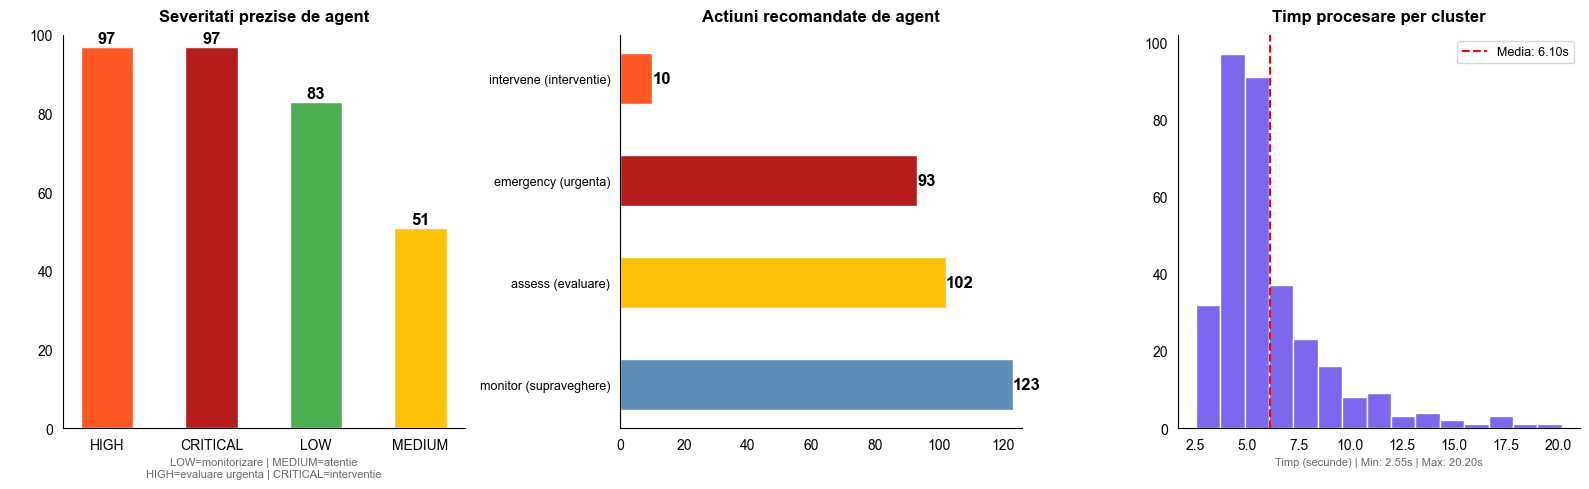

Salvat: agentResults.png


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.patch.set_facecolor('white')
for ax in axes:
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(colors='black')
    for spine in ax.spines.values():
        spine.set_edgecolor('black')

# Severitati
sev_colors = {'LOW': '#4CAF50', 'MEDIUM': '#FFC107', 'HIGH': '#FF5722', 'CRITICAL': '#B71C1C'}
sev_counts = df_agent['severity'].value_counts()

x_pos = range(len(sev_counts))
bars = axes[0].bar(x_pos, sev_counts.values,
    color=[sev_colors.get(s, 'gray') for s in sev_counts.index],
    edgecolor='white', width=0.5)

axes[0].set_xticks(list(x_pos))
axes[0].set_xticklabels(list(sev_counts.index), fontsize=10)
axes[0].set_ylim(0, max(sev_counts.values) + 3)
axes[0].set_title('Severitati prezise de agent', fontweight='bold', pad=10)
axes[0].set_ylabel('Nr. clustere')
axes[0].set_xlabel('LOW=monitorizare | MEDIUM=atentie\nHIGH=evaluare urgenta | CRITICAL=interventie',
                   fontsize=8, color='dimgray')

for bar, val in zip(bars, sev_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.1,
                 str(val), ha='center', va='bottom', fontweight='bold', fontsize=12)


# Actiuni recomandate
action_counts = df_agent['action_required'].value_counts()
action_labels = {
    'none': 'none (nicio actiune)',
    'monitor': 'monitor (supraveghere)',
    'assess': 'assess (evaluare)',
    'intervene': 'intervene (interventie)',
    'emergency': 'emergency (urgenta)'
}
action_colors = {
    'none': '#90EE90', 'monitor': '#5B8DB8',
    'assess': '#FFC107', 'intervene': '#FF5722', 'emergency': '#B71C1C'
}

labels = [action_labels.get(a, a) for a in action_counts.index]
colors_h = [action_colors.get(a, 'gray') for a in action_counts.index]

y_pos = range(len(action_counts))
bars_h = axes[1].barh(list(y_pos), action_counts.values,
                      color=colors_h, edgecolor='white', height=0.5)
axes[1].set_yticks(list(y_pos))
axes[1].set_yticklabels(labels, fontsize=9)
axes[1].set_xlim(0, max(action_counts.values) + 3)
axes[1].set_title('Actiuni recomandate de agent', fontweight='bold', pad=10)
axes[1].set_xlabel('Nr. clustere', fontsize=9)

for bar, val in zip(bars_h, action_counts.values):
    axes[1].text(bar.get_width() + 0.1,
                 bar.get_y() + bar.get_height()/2,
                 str(val), va='center', fontweight='bold', fontsize=12)


# Timp procesare
mean_t = df_agent['processing_time_s'].mean()
axes[2].hist(df_agent['processing_time_s'], bins=15, color='#7B68EE', edgecolor='white')
axes[2].axvline(mean_t, color='red', linestyle='--', linewidth=1.5,
                label=f'Media: {mean_t:.2f}s')
axes[2].set_title('Timp procesare per cluster', fontweight='bold', pad=10)
axes[2].set_ylabel('Nr. clustere')
axes[2].set_xlabel(f'Timp (secunde) | Min: {df_agent["processing_time_s"].min():.2f}s'
                   f' | Max: {df_agent["processing_time_s"].max():.2f}s',
                   fontsize=8, color='dimgray')
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig('../data/results/agentResults.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Salvat: agentResults.png')

#### Verificare tool call completeness

Agentul trebuie sa apeleze **toate 3 tool-urile** pentru fiecare cluster. Verificam:

In [18]:
all_tools = {'classify_severity', 'generate_unified_alarm', 'explain_grouping'}

complete   = sum(1 for r in agent_results if all_tools.issubset(set(r.tools_called)))
incomplete = len(agent_results) - complete

print(f'Tool call completeness: {complete}/{len(agent_results)} '
      f'({100*complete/len(agent_results):.1f}%)')

if incomplete > 0:
    print(f'\nClustre cu tool-uri lipsa:')
    for r in agent_results:
        missing = all_tools - set(r.tools_called)
        if missing:
            print(f'  Cluster #{r.cluster_id}: lipsesc {missing}')

Tool call completeness: 328/328 (100.0%)


## Salvare rezultate

In [19]:
# DataFrame rezultate agent
df_agent.to_csv('../data/results/agent_results.csv', index=False)
print('Salvat: agent_results.csv')

# Versiunea JSON (mai usor de inspectat)
agent_results_json = [r.to_dict() for r in agent_results]
with open('../data/results/agent_results.json', 'w', encoding='utf-8') as f:
    json.dump(agent_results_json, f, indent=2, default=str)
print('Salvat: agent_results.json')

Salvat: agent_results.csv
Salvat: agent_results.json


## Rezumat Etapa 3

**Fisiere salvate:**
```
data/processed/alarms_deduplicated.csv      <- df adnotat cu cluster_id etc.
data/results/agent_results.csv              <- rezultatele agentului
data/results/agent_results.json             <- acelasi, format JSON
data/results/plot_cluster_distribution.png
data/results/plot_agent_results.png
```

In [21]:
print('Rezumat Etapa 3 - Agent')
print(f'  Alarme totale           : {len(df)}')
print(f'  Clustere formate        : {len(dedup.clusters)}')
print(f'  Clustere cu duplicate   : {len(dup_clusters)}')
print(f'  Alarme suprimate        : {dedup.stats()["alarms_suppressed"]}')
print(f'  Deduplication rate      : {dedup.deduplication_rate():.2%}')
print(f'  Clustere procesate agent: {len(agent_results)}')
n_ok = sum(1 for r in agent_results if r.success)
print(f'  Agent success rate      : {n_ok}/{len(agent_results)} ({100*n_ok/len(agent_results):.1f}%)')
print()
print('Fisiere salvate:')
print('  data/processed/alarms_deduplicated.csv')
print('  data/results/agent_results.csv')
print('  data/results/agent_results.json')
print('  data/results/clusterDistribution.png')
print('  data/results/agentResults.png')

Rezumat Etapa 3 - Agent
  Alarme totale           : 1750
  Clustere formate        : 556
  Clustere cu duplicate   : 328
  Alarme suprimate        : 1194
  Deduplication rate      : 68.23%
  Clustere procesate agent: 328
  Agent success rate      : 328/328 (100.0%)

Fisiere salvate:
  data/processed/alarms_deduplicated.csv
  data/results/agent_results.csv
  data/results/agent_results.json
  data/results/clusterDistribution.png
  data/results/agentResults.png
